In [2]:
!pip -q install tensorflow scikit-learn pandas matplotlib

import pandas as pd

fake = [
    "Scientists confirm miracle drink cures every disease",
    "Celebrity reveals shocking secret hidden for years",
    "Government secretly plans to control everyone's dreams",
    "Aliens visited earth yesterday according to rumours",
    "Miracle medicine guarantees instant weight loss",
] * 200

real = [
    "The government announced a new education policy today",
    "Researchers published their findings in a scientific journal",
    "The weather department issued a rainfall warning",
    "The university announced examination dates for students",
    "The health department released its annual report",
] * 200

df = pd.DataFrame({
    "text": fake + real,
    "label": [0]*len(fake) + [1]*len(real)
}).sample(frac=1, random_state=42).reset_index(drop=True)

print(df.shape)
print(df.head())

(2000, 2)
                                                text  label
0  The government announced a new education polic...      1
1  Aliens visited earth yesterday according to ru...      0
2  The university announced examination dates for...      1
3  Scientists confirm miracle drink cures every d...      0
4   The health department released its annual report      1


In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

X = df["text"].values
y = df["label"].values

tokenizer = Tokenizer(num_words=1000, oov_token="<OOV>")
tokenizer.fit_on_texts(X)

sequences = tokenizer.texts_to_sequences(X)

X_pad = pad_sequences(
    sequences, maxlen=20, padding="post", truncating="post"
)

X_train, X_test, y_train, y_test = train_test_split(
    X_pad, y, test_size=0.2, random_state=42, stratify=y
)

print("Padded data:", X_pad.shape)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Padded data: (2000, 20)
Training data: (1600, 20)
Testing data: (400, 20)


In [4]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

model = Sequential([
    Embedding(input_dim=1000, output_dim=32),
    LSTM(32),
    Dropout(0.2),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1
)


Epoch 1/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.7347 - loss: 0.4947 - val_accuracy: 1.0000 - val_loss: 0.0777
Epoch 2/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 1.0000 - loss: 0.0290 - val_accuracy: 1.0000 - val_loss: 0.0107
Epoch 3/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 1.0000 - loss: 0.0078 - val_accuracy: 1.0000 - val_loss: 0.0045
Epoch 4/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 1.0000 - loss: 0.0043 - val_accuracy: 1.0000 - val_loss: 0.0028
Epoch 5/5
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 1.0000 - loss: 0.0029 - val_accuracy: 1.0000 - val_loss: 0.0020


In [5]:
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score, confusion_matrix

y_prob = model.predict(X_test, verbose=0)
y_pred = (y_prob >= 0.5).astype(int).ravel()

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0
Confusion Matrix:
 [[200   0]
 [  0 200]]


In [6]:
article = [
    "Scientists discovered a new treatment after conducting research"
]

seq = tokenizer.texts_to_sequences(article)

padded = pad_sequences(
    seq, maxlen=20, padding="post", truncating="post"
)

prediction = model.predict(padded, verbose=0)[0][0]

if prediction >= 0.5:
    print("Prediction: Real News")
else:
    print("Prediction: Fake News")

print("Real news probability:", prediction)

Prediction: Real News
Real news probability: 0.9978681


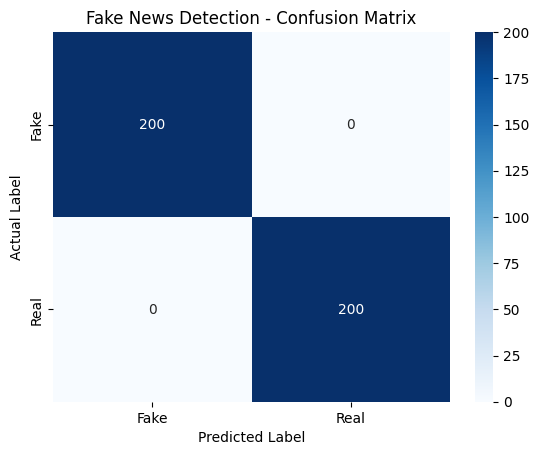

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Fake", "Real"],
    yticklabels=["Fake", "Real"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Fake News Detection - Confusion Matrix")
plt.show()

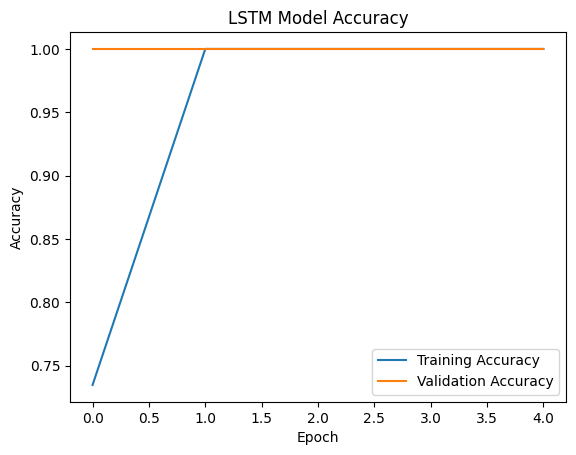

In [8]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM Model Accuracy")
plt.legend()
plt.show()

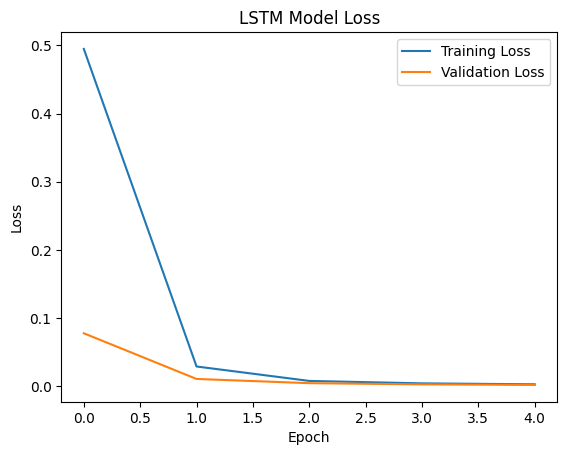

In [9]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM Model Loss")
plt.legend()
plt.show()